In [1]:
import os, os.path
import rasterio as rio
from rasterio.windows import Window
from osgeo import gdal
from osgeo.gdalconst import *
from matplotlib import pyplot as plt
import numpy as np
import time
import math
from rasterio.warp import calculate_default_transform, reproject, Resampling
from pyproj import CRS

In [2]:
### For the tree canopy SVFs, need to use a dsm with only the trees, where there are no trees the dsm is 0, where there are trees it is tree height

#### !!!! Run the below code in bash to create the merged tree height for files where GEE splits it into multiple ####

for city_name in ["Baltimore"]:
    
    # Input and output paths

    #if city_name == "Phoenix":
    #    input_tif == "/work/users/s/b/sberk/other_cities/input_rasters/Phoenix_Tree_height.vrt"

    #else: 
    #    input_tif = f"/work/users/s/b/sberk/other_cities/input_rasters/{city_name}_Tree_height.tif"
    
    input_tif = f"/work/users/s/b/sberk/other_cities/input_rasters/{city_name}_Tree_height.tif"
    reprojected_tif = f"/work/users/s/b/sberk/other_cities/input_rasters/{city_name}_Tree_height_utm.tif"
    output_folder = f"/work/users/s/b/sberk/other_cities/{city_name}/tree_height_tiles"


    with rio.open(input_tif) as src:
        src_crs = CRS.from_wkt(src.crs.wkt)
        bounds = src.bounds
    
        # centroid lat/lon to be the reference for the local crs 
        lon_center = (bounds.left + bounds.right) / 2
        lat_center = (bounds.bottom + bounds.top) / 2
    
        # Compute UTM zone
        utm_zone = int((lon_center + 180) / 6) + 1
        hemisphere = "north" if lat_center >= 0 else "south"
    
        # Build UTM CRS
        utm_crs = CRS.from_dict({
            "proj": "utm",
            "zone": utm_zone,
            "south": hemisphere == "south"
        })
    
        print(f"Detected UTM CRS: {utm_crs.to_string()}")
    
        # Calculate transform
        transform, width, height = calculate_default_transform(
            src.crs, utm_crs, src.width, src.height, *src.bounds
        )
    
        kwargs = src.meta.copy()
        kwargs.update({
            'crs': utm_crs,
            'transform': transform,
            'width': width,
            'height': height,
            'nodata': 0   # height is zero where there is not data 
        })

        os.makedirs(os.path.dirname(reprojected_tif), exist_ok=True)

        with rio.open(reprojected_tif, 'w', **kwargs) as dst:
            for i in range(1, src.count + 1):
                reproject(
                    source=rio.band(src, i),
                    destination=rio.band(dst, i),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=transform,
                    dst_crs=utm_crs,
                    resampling=Resampling.nearest
                )

    print("Reprojection to local crs/ meters complete")

    # Tile and buffer size in meters
    tile_size_m = 1300 
    buffer_m = 150

    # Create the output folder if it doesn't exist
    os.makedirs(output_folder, exist_ok=True)

    # Open the input raster (should be in local crs in meters) 
    with rio.open(reprojected_tif) as src:
    #with rio.open(vrt_path) as src:   # if you are only using one tif file you can replace vrt_path with reprojected_tif and uncomment it above
        transform = src.transform
        crs = src.crs
        bounds = src.bounds
        minx, miny, maxx, maxy = bounds
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
        print("Resolution:", src.res)
    
        # Calculate number of tiles in X and Y directions
        num_tiles_x = int(np.ceil((maxx - minx - tile_size_m) / (tile_size_m - buffer_m)))
        num_tiles_y = int(np.ceil((maxy - miny - tile_size_m) / (tile_size_m - buffer_m)))

        print(f"Image size: {src.width} x {src.height} pixels")
        print(f"Total tiles: {num_tiles_x} x {num_tiles_y}")

        # Iterate over tiles
        for i in range(num_tiles_x):
            for j in range(num_tiles_y):
                x_off = minx + i * (tile_size_m - buffer_m)
                y_off = miny + j * (tile_size_m - buffer_m)
                x_end = min(maxx, x_off + tile_size_m)
                y_end = min(maxy, y_off + tile_size_m)

                # Get window in pixel coordinates
                window = src.window(x_off, y_off, x_end, y_end)

                # Read data in window
                tile_data = src.read(1, window=window)
                # Skip tile if any values are NaN - these will be tiles right at the edge so not important (as there was a buffer) and they mess up the svf calc code later
                if np.isnan(tile_data).any():
                    print(f"Skipping tile {i}_{j} (contains NaN)")
                    continue
            
                # Output path
                output_filename = os.path.join(output_folder, f"tile_{i}_{j}.tif")

                # Write tile
                with rio.open(
                    output_filename, 'w',
                    driver='GTiff',
                    count=1,
                    dtype=tile_data.dtype,
                    width=tile_data.shape[1],
                    height=tile_data.shape[0],
                    crs=crs,
                    transform=src.window_transform(window)
                ) as dst:
                    dst.write(tile_data, 1)
                    
                    print(f"Size{tile_data.shape[1]} x {tile_data.shape[0]} pixels")
                print(f"Written tile {i}_{j} to {output_filename}")
            
    print(f"Tiling completed for {city_name}")


Detected UTM CRS: +proj=utm +zone=18 +type=crs
Reprojection to local crs/ meters complete
CRS: EPSG:32618
Bounds: BoundingBox(left=352223.24776163104, bottom=4339779.518869245, right=368236.3508251806, top=4359456.847925193)
Resolution: (0.8887281087551094, 0.8887281087551094)
Image size: 18018 x 22141 pixels
Total tiles: 13 x 16
Size1463 x 1463 pixels
Written tile 0_0 to /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_0.tif
Size1463 x 1463 pixels
Written tile 0_1 to /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_1.tif
Size1463 x 1463 pixels
Written tile 0_2 to /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_2.tif
Size1463 x 1463 pixels
Written tile 0_3 to /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_3.tif
Size1463 x 1463 pixels
Written tile 0_4 to /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_4.tif
Size1463 x 1463 pixels
Written tile 0_5 to /work/users/s/b/sberk/other_ci

In [1]:
import os, os.path
import rasterio as rio
from osgeo import gdal
from osgeo.gdalconst import *

from pycuda.compiler import SourceModule
import pycuda
from pycuda import gpuarray
from pycuda import compiler
import pycuda.driver as cuda
import pycuda.autoinit             # PyCuda autoinit
import pycuda.driver as cuda       # PyCuda In, Out helpers
import matplotlib.pyplot as plot   # Library to plot
import matplotlib.cm as colormap   # Library to plot
import time
import numpy as np                     # numeric python lib
import matplotlib.image as mpimg       # reading images to numpy arrays
import matplotlib.pyplot as plt        # to plot any graph
import matplotlib.patches as mpatches  # to draw a circle at the mean contour
import scipy.ndimage as ndi            # to determine shape centrality
# matplotlib setup
%matplotlib inline
from pylab import rcParams
rcParams['figure.figsize'] = (8, 8)      # setting default size of plots


print("%d device(s) found." % cuda.Device.count())           
for ordinal in range(cuda.Device.count()):
    dev = cuda.Device(ordinal)
    print ("Device #%d: %s" % (ordinal, dev.name()))
print (cuda)

1 device(s) found.
Device #0: NVIDIA A100-PCIE-40GB MIG 2g.10gb
<module 'pycuda.driver' from '/nas/longleaf/home/sberk/.conda/envs/solweig_env2/lib/python3.9/site-packages/pycuda/driver.py'>


In [2]:

    
    #Kernel text
kernel = """

#include <math.h>

#define _X  ( threadIdx.x + blockIdx.x * blockDim.x )
#define _Y  ( threadIdx.y + blockIdx.y * blockDim.y )
#define _WIDTH  ( blockDim.x * gridDim.x )
#define _HEIGHT ( blockDim.y * gridDim.y  )
#define _XM(x)  ( (x + _WIDTH) % _WIDTH )
#define _YM(y)  ( (y + _HEIGHT) % _HEIGHT )
#define _INDEX(x,y)  ( _XM(x)  + _YM(y) * _WIDTH )
#define PI 3.1415926


//https://github.com/AlainPaillou/PyCuda_Denoise_Filters/blob/master/PyCuda_KNN_Denoise_Mono.py
__global__ void svfcalculator(float * lattice_out, float * lattice, float scale,int imageW, int imageH) //int w, int h
{
    #define NLM_BLOCK_RADIUS    3
    
    int rangeDist = 50; // changed this to 50m distance (from 150)
    
    //int imageW = 1300;
    //int imageH = 1300;
    
    const long int   ix = blockDim.x * blockIdx.x + threadIdx.x;
    const long int   iy = blockDim.y * blockIdx.y + threadIdx.y;
    const float  x = (float)ix  + 1.0f;
    const float  y = (float)iy  + 1.0f;
    const float limxmin = -1;      //NLM_BLOCK_RADIUS + 2;
    const float limxmax = imageW; // - NLM_BLOCK_RADIUS - 2;
    const float limymin = -1;      //NLM_BLOCK_RADIUS + 2;
    const float limymax = imageH; // - NLM_BLOCK_RADIUS - 2;
    
    long int index4;    
    
    
    if(ix>limxmin && ix<limxmax && iy>limymin && iy<limymax){
        // sky view factor
        float SVF_res = 0;
        
        //Result accumulator
        float clr00 = 0.0;
        float clrIJ = 0.0;
        
        //Center of the KNN window
        index4 = x + (y * imageW);
        
        // the current pixel - set the height to 2m to simulate a pedestrian instead of using the pixel height
        //clr00 = lattice[index4]; //this is for the building svfs
        clr00 = 1.5f; // look at the svfs at 1.5m height for tree canopies - ensure input just tree canopy heights 
        
        for(int thetaN =0; thetaN<360; thetaN++) 
        {
            float theta = PI*float(thetaN)/180;
            float betaMax = 0;
            
            for( float radius = 1; radius < rangeDist; radius = radius + 1) //changed this from 5m to 1m increments
            {   
                // this is important or you will have memory error
                if (x + int(radius*cos(theta)) > limxmax | x + int(radius*cos(theta)) < limxmin | y - int(radius*sin(theta)) > limymax | y - int(radius*sin(theta)) < 0) 
                {
                    break;
                }
            
                long int index2 = x + int(radius*cos(theta)) + (y - int(radius*sin(theta))) * imageW;
                clrIJ = lattice[index2];
                
                // building height information
                float buildH = clrIJ - clr00;
                
                float beta = atan(buildH/radius); 
                if (betaMax < beta)
                {
                    betaMax = beta;
                }
            }
            SVF_res += pow(cos(betaMax), 2);
        }
        
        lattice_out[index4] = SVF_res/360.0;
    }
    
}
"""


#Compile and get kernel function
mod = SourceModule(kernel)
print (mod)

In [3]:
import PIL
from PIL import Image as PILImage
import rasterio as rio
import numpy as np
import pycuda.driver as drv


def svfCalculator_RayTracingOnGPU(dsm, scale):
    '''This code is used to calculate the sky view factor using the ray-tracing
    algorithm based on the GPU acceleration
    last modified Jan 27, 2021
    by Xiaojiang Li, Temple University
    
    Parameters:
        dsm: the numpy array of the digital surface model
        scale: is the scale of the image, read from the gdal,
                1px of 2 feet, scale is 0.5; 1px of 3 feet, scale is 0.3333 
    '''
    
    # Ensure DSM is a numpy array and remove negative values
    px = np.array(dsm).astype(np.float32)
    px[px < 0] = 0  # Set negative DSM values to 0
    
    # Ensure no NaN or Inf values in the DSM
    px = np.nan_to_num(px, nan=0, posinf=0, neginf=0)
    
    #print ('Size:' + str(dsm.shape))
    #print ('Pixels:' + str (dsm.shape[0]*dsm.shape[1]))
    #print('The px.nbtyle is:', px.nbytes, px.shape)
    
    # Check GPU memory capacity
    if px.nbytes > cuda.mem_get_info()[0]:
        raise MemoryError("The DSM is too large for available GPU memory.")

    # allocate memory on the device and transfer data to GPU 
    d_px = cuda.mem_alloc(px.nbytes)
    cuda.memcpy_htod(d_px, px)
    
    height,width = px.shape
    nb_pixels = height * width
    
    # Set blocks et Grid sizes
    nb_ThreadsX = 8
    nb_ThreadsY = 8
    #nb_blocksX = (width // nb_ThreadsX) + 1
    #nb_blocksY = (height // nb_ThreadsY) + 1
    nb_blocksX = (width  + nb_ThreadsX - 1) // nb_ThreadsX
    nb_blocksY = (height + nb_ThreadsY - 1) // nb_ThreadsY
    

    #print("Test GPU ",nb_blocksX*nb_blocksY," Blocks ",nb_ThreadsX*nb_ThreadsY," Threads/Block")
    tps1 = time.time()
    
    
    # create empty array
    lattice_gpu = gpuarray.to_gpu(px)
    newLattice_gpu = gpuarray.empty_like(lattice_gpu)
    
    # the GPU function
    KNN_Mono_GPU = mod.get_function("svfcalculator")
    #KNN_Mono_GPU(newLattice_gpu, d_px, block=(nb_ThreadsX, nb_ThreadsY, 1), grid=(nb_blocksX, nb_blocksY))
    KNN_Mono_GPU(newLattice_gpu, d_px, np.float32(scale), np.int32(width), np.int32(height),\
               block=(nb_ThreadsX,nb_ThreadsY,1), \
               grid=(nb_blocksX,nb_blocksY)) 
    
    
    bwPx = np.empty_like(px)    
    bwPx = newLattice_gpu.get()
    
    bwPx = np.float32(bwPx)
    #pil_im = PILImage.fromarray(bwPx)
    
    return bwPx


## function to save the numpy as a geotiff
def saverasternd(gdal_data, filename, raster):
    rows = gdal_data.RasterYSize
    cols = gdal_data.RasterXSize
    
    outDs = gdal.GetDriverByName("GTiff").Create(filename, cols, rows, int(1), GDT_Float32)
    outBand = outDs.GetRasterBand(1)
    
    # write the data
    outBand.WriteArray(raster, 0, 0)
    # flush data to disk, set the NoData value and calculate stats
    outBand.FlushCache()
    outBand.SetNoDataValue(-9999)
    
    # georeference the image and set the projection
    outDs.SetGeoTransform(gdal_data.GetGeoTransform())
    outDs.SetProjection(gdal_data.GetProjection())

In [4]:

for city_name in [ "Baltimore"]:    
    root = f"/work/users/s/b/sberk/other_cities/{city_name}/tree_height_tiles"
    outroot = f"/work/users/s/b/sberk/other_cities/{city_name}/tree_svf_tiles"

    if not os.path.exists(outroot):
        os.mkdir(outroot)

    files = [file for file in os.listdir(root) if file.endswith(".tif")]    
    
    for file in files:
        filename = os.path.join(root, file)
        t0 = time.time()
    
        ### using gdal to read the raster dsm
        gdal_dsm = gdal.Open(filename)
        dsm_img = gdal_dsm.ReadAsArray().astype(float)
        dsm_img = np.clip(dsm_img - 2.0, a_min=0, a_max=None) # looking at the 2m height to similar pedestrian level
        geotransform = gdal_dsm.GetGeoTransform()
        #scale = 1 / geotransform[1] # geotransform[1] is the pixel size
        scale = geotransform[1]
        ## calculate the svf
        svfres = svfCalculator_RayTracingOnGPU(dsm_img, scale)
        print('The time and file are:', time.time() - t0, filename)
    
        outsvfname = os.path.join(outroot, 'svf_' + file)
        saverasternd(gdal_dsm, outsvfname, np.asarray(svfres))
    
    print(f'{city_name} SVF calculations complete')

The time and file are: 1.9361176490783691 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_0.tif
The time and file are: 1.7737462520599365 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_1.tif
The time and file are: 1.7625162601470947 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_10.tif
The time and file are: 1.7678284645080566 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_11.tif
The time and file are: 1.7619085311889648 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_12.tif
The time and file are: 1.7587406635284424 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_13.tif
The time and file are: 1.764322280883789 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_14.tif
The time and file are: 1.7636232376098633 /work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_0_15.tif
The time and file are: 1.7616562843322754 /work/use

In [5]:
#import os
#import rasterio as rio
from rasterio.windows import Window

# crop the buffer from the svf tiles (it contains artifacts from edge effects)
for city_name in ["Baltimore"]:

    input_tiles_folder = f"/work/users/s/b/sberk/other_cities/{city_name}/tree_svf_tiles"
    cropped_tiles_folder = f"/work/users/s/b/sberk/other_cities/{city_name}/tree_svf_tiles_cropped"

    os.makedirs(cropped_tiles_folder, exist_ok=True)

    tile_size_m = 1300
    buffer_m = 150
    core_size_m = tile_size_m - 2 * buffer_m   # 1000 m

    for fname in os.listdir(input_tiles_folder):
        if not fname.endswith(".tif"):
            continue

        in_path = os.path.join(input_tiles_folder, fname)
        out_path = os.path.join(cropped_tiles_folder, fname.replace(".tif", "_core.tif"))

        with rio.open(in_path) as src:
            res_x, res_y = src.res  # meters per pixel
            buffer_px_x = int(buffer_m / res_x)
            buffer_px_y = int(buffer_m / abs(res_y))

            core_px_x = int(core_size_m / res_x)
            core_px_y = int(core_size_m / abs(res_y))

            # Window that removes buffer
            window = Window(
                col_off=buffer_px_x,
                row_off=buffer_px_y,
                width=core_px_x,
                height=core_px_y
            )

            data = src.read(1, window=window)
            transform = src.window_transform(window)

            meta = src.meta.copy()
            meta.update({
                "height": data.shape[0],
                "width": data.shape[1],
                "transform": transform
            })

            with rio.open(out_path, "w", **meta) as dst:
                dst.write(data, 1)

    print(f"Cropped buffers for {city_name}")


Cropped buffers for Baltimore


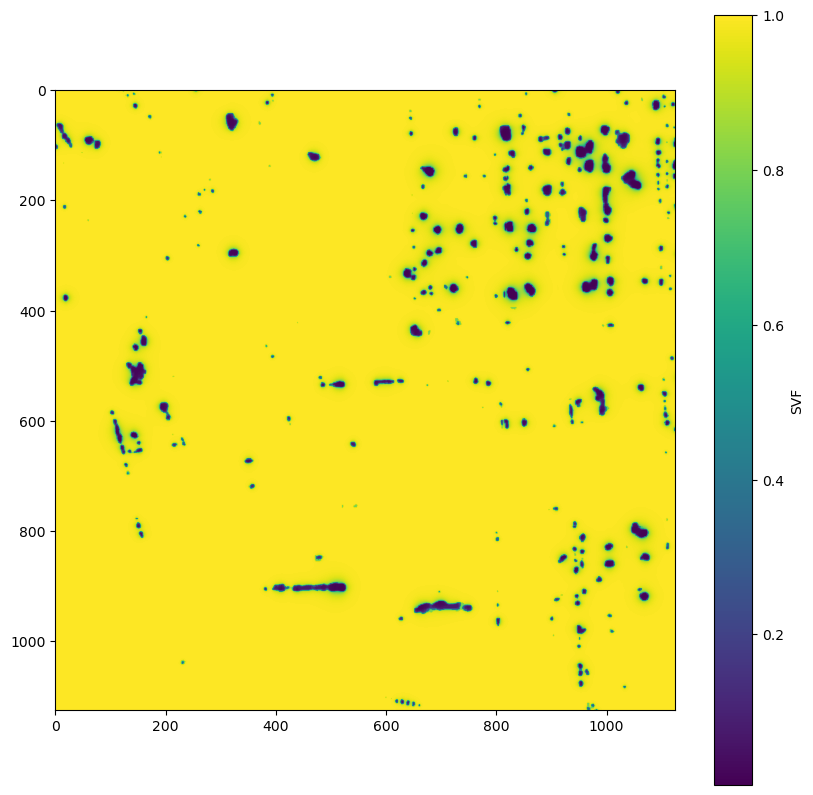

In [30]:
dsmfile = '/work/users/s/b/sberk/other_cities/Baltimore/tree_svf_tiles_cropped/svf_tile_8_8_core.tif'
#dsmfile = '/work/users/s/b/sberk/other_cities/Baltimore/tree_height_tiles/tile_9_9.tif'
with rio.open(dsmfile) as dsmlayer:
    dsmimg = dsmlayer.read(1)

gdal_dsm = gdal.Open(dsmfile)
dsm = gdal_dsm.ReadAsArray().astype(float)#dsm
geotransform = gdal_dsm.GetGeoTransform()
scale = 1 / geotransform[1]

plt.figure(figsize=(10, 10))
plt.imshow(dsm)
plt.colorbar(label='SVF')

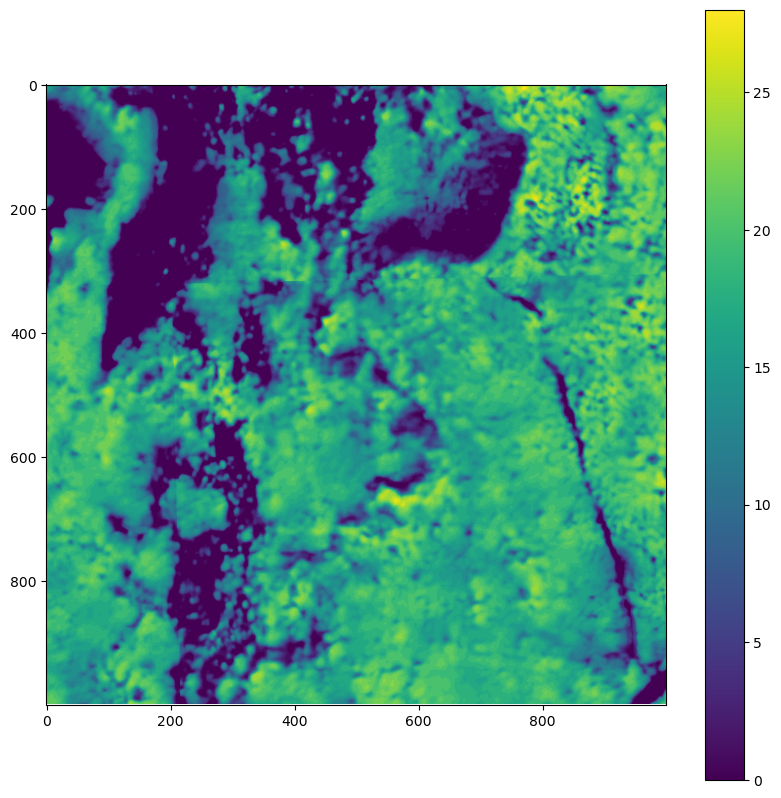

In [25]:
dsmfile = '/nas/longleaf/home/sberk/SVF_for_Durham_ML/tree_dsm_tiles/tile_1_1.tif'
#dsmfile ='/nas/longleaf/home/sberk/SVF_for_Durham_ML/building_dsm_tiles/tile_12_12.tif'

with rio.open(dsmfile) as dsmlayer:
    dsmimg = dsmlayer.read(1)

gdal_dsm = gdal.Open(dsmfile)
dsm = gdal_dsm.ReadAsArray().astype(float)#dsm
geotransform = gdal_dsm.GetGeoTransform()
scale = 1 / geotransform[1]

plt.figure(figsize=(10, 10))
plt.imshow(dsm)

plt.colorbar()

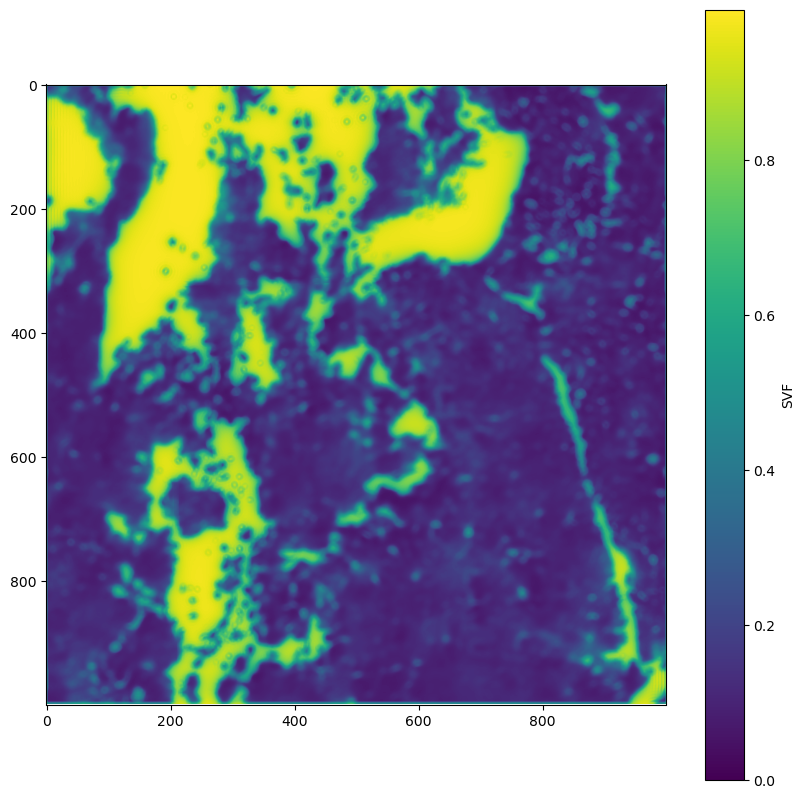

In [26]:
dsmfile = '/nas/longleaf/home/sberk/SVF_for_Durham_ML/tree_svf_tiles/svf_tile_1_1.tif'


with rio.open(dsmfile) as dsmlayer:
    dsmimg = dsmlayer.read(1)

gdal_dsm = gdal.Open(dsmfile)
dsm = gdal_dsm.ReadAsArray().astype(float)#dsm
geotransform = gdal_dsm.GetGeoTransform()
scale = 1 / geotransform[1]

plt.figure(figsize=(10, 10))
plt.imshow(dsm)
plt.colorbar(label='SVF')